# 01 — Exploratory Data Analysis (EDA)

Mục tiêu: hiểu dataset TRƯỚC KHI train, để trả lời 4 câu hỏi:
1. Phân bố nhãn O / B-SKILL / I-SKILL? (mất cân bằng class?)
2. Độ dài câu? (chọn `max_length` bao nhiêu?)
3. Top skills là gì? (model sẽ "ăn" nhiều nhất món gì?)
4. Test có skill nào mà train chưa từng thấy? (đoán trước recall mất ở đâu?)

Mỗi cell code bên dưới đều là TODO — bạn tự viết, gợi ý đã cho sẵn.

## 0. Chuẩn bị: load 3 file split

Cấu trúc mỗi file: list các `{"tokens": [...], "labels": [...]}`.

In [1]:
import json
from collections import Counter
from pathlib import Path

split_dir = Path("../data/splits")

with (
    open(split_dir / "train.json", encoding="utf-8") as f_train,
    open(split_dir / "val.json", encoding="utf-8") as f_val,
    open(split_dir / "test.json", encoding="utf-8") as f_test,
):
    train = json.load(f_train)
    val = json.load(f_val)
    test = json.load(f_test)

# 0a: load train/val/test json tu data/splits/ vao 3 bien train, val, test
# Goi y: json.load(open(path, encoding="utf-8"))

# 0b: in so cau cua moi split. Ky vong: 244 / 52 / 54
print(f"Loaded: {len(train)} train, {len(val)} val, {len(test)} test samples.")


Loaded: 244 train, 52 val, 54 test samples.


## 1. Phân bố nhãn

Đếm số token O / B-SKILL / I-SKILL trên từng split, vẽ bar chart.
Câu hỏi cần trả lời: O chiếm bao nhiêu %? Điều đó báo hiệu vấn đề gì khi train?

Tỉ lệ label 'O' trên train: 0.928


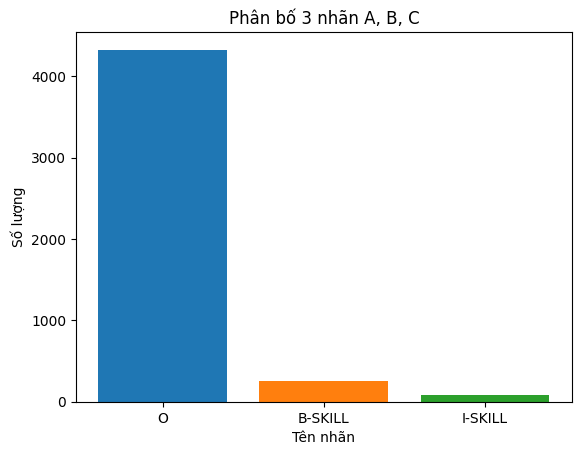

In [2]:
import matplotlib.pyplot as plt
from collections import Counter

# TODO 1a: viet ham count_labels(split) -> Counter dem label cua toan split
# Goi y: Counter(l for s in split for l in s["labels"])
def count_labels(split): 
    return Counter(l for s in split for l in s["labels"])

# TODO 1b: tinh ti le O tren train, in ra dang 0.xxx
train_counts = count_labels(train)
total_labels = sum(train_counts.values())
o_ratio = train_counts["O"] / total_labels
print(f"Tỉ lệ label 'O' trên train: {o_ratio:.3f}")
# TODO 1c: ve bar chart 3 nhan cho train (plt.bar)
labels = list(train_counts.keys())
values = list(train_counts.values())

plt.bar(labels, values, color=['#1f77b4', '#ff7f0e', '#2ca02c'])

plt.title("Phân bố 3 nhãn A, B, C")
plt.xlabel("Tên nhãn")
plt.ylabel("Số lượng")

plt.show()


## 2. Độ dài câu

Histogram số token / câu cho từng split.
Câu hỏi cần trả lời: câu dài nhất bao nhiêu token? Chọn `max_length` bao nhiêu thì không cắt cụt mà cũng không phí VRAM?

[train] Min: 2 | Max: 92 | Mean: 19.10
[val] Min: 2 | Max: 48 | Mean: 17.42
[test] Min: 5 | Max: 57 | Mean: 21.30


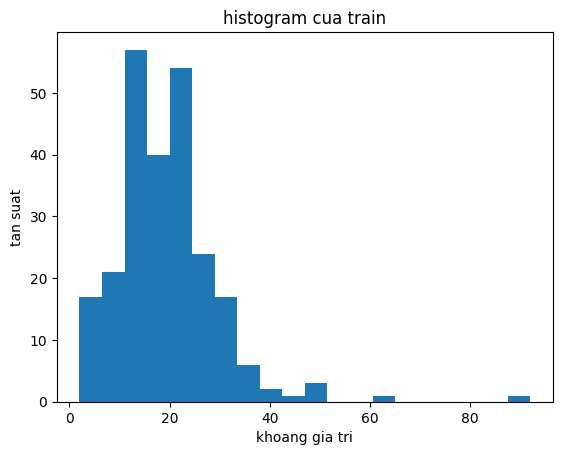

In [3]:
# TODO 2a: tinh list do dai cau: [len(s["tokens"]) for s in train], tuong tu val/test
len_train = [len(s["tokens"]) for s in train]
len_val = [len(s["tokens"]) for s in val]
len_test = [len(s["tokens"]) for s in test]
# TODO 2b: in min / max / trung binh moi split
splits = {
    "train" : len_train,
    "val" : len_val,
    "test" : len_test
}

for name, lengths in splits.items():
    if lengths:
        min_len = min(lengths)
        max_len = max(lengths)
        avg_len = sum(lengths) / len(lengths)
        print(f"[{name}] Min: {min_len} | Max: {max_len} | Mean: {avg_len:.2f}")
    else:
        print(f"[{name}] Split rỗng")

# TODO 2c: ve histogram do dai cau cua train (plt.hist, bins=20)
plt.hist(len_train, bins=20)
plt.title("histogram cua train")
plt.xlabel("khoang gia tri")
plt.ylabel("tan suat")
plt.show()


## 3. Top skills

Gộp các token B-SKILL + I-SKILL liên tiếp thành span (vd. ["Spring", "Boot"] -> "Spring Boot"), đếm tần suất trên train.
Câu hỏi cần trả lời: top 15 là gì? Nhóm nào áp đảo (backend? devops? ML?) — model sẽ giỏi nhóm đó nhất.

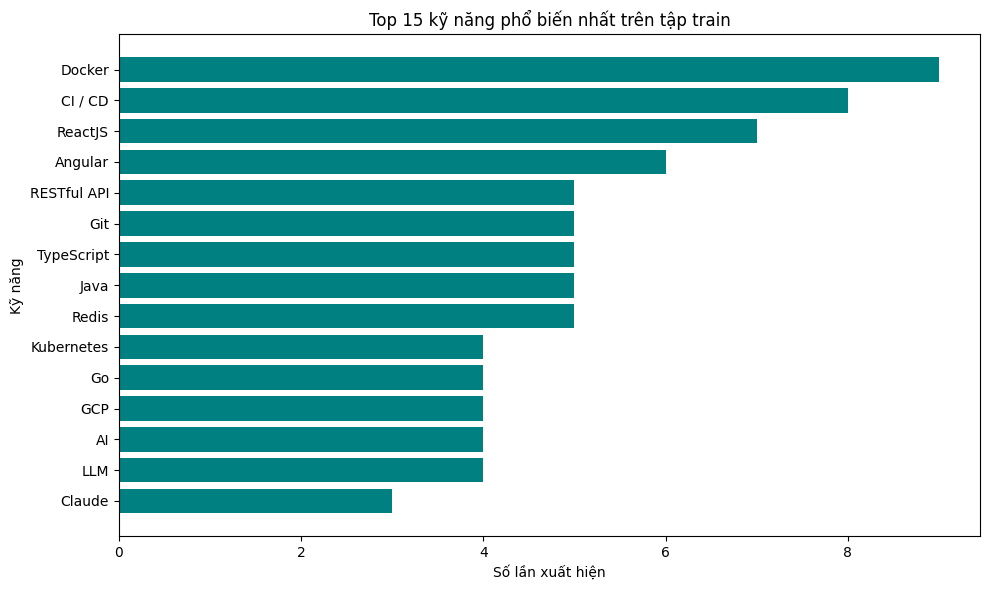

In [4]:
# TODO 3a: viet ham extract_spans(split) -> list cac skill dang chuoi
# Logic: gap token B-SKILL thi bat dau span moi; I-SKILL thi noi vao span hien tai; O thi dong span lai
# Goi y: duyet tung cau, giu bien current = [] de gop token
def extract_spans(split):
    skills = []
    for s in split:
        span = []
        for token, label in zip(s["tokens"], s["labels"]):
            if label == "B-SKILL":
                if span:
                    skills.append(" ".join(span))
                span = [token]
            elif label == "I-SKILL":
                if span:
                    span.append(token)
            else: # label == "O"
                if span:
                    skills.append(" ".join(span))
                    span = []
        # Lưu lại span nếu token cuối câu là skill
        if span:
            skills.append(" ".join(span))
    return skills
# TODO 3b: Counter(extract_spans(train)).most_common(15) va ve bar chart ngang (plt.barh)
train_skills = extract_spans(train)
top15 = Counter(train_skills).most_common(15)

skills, counts = zip(*top15[::-1])

plt.figure(figsize=(10, 6))
plt.barh(skills, counts, color="teal")
plt.title("Top 15 kỹ năng phổ biến nhất trên tập train")
plt.xlabel("Số lần xuất hiện")
plt.ylabel("Kỹ năng")
plt.tight_layout()
plt.show()


## 4. Skill trong test mà train chưa từng thấy (OOV)

Model NER học pattern từ train — skill hoàn toàn mới ở test sẽ khó bắt (recall mất ở đây).
Câu hỏi cần trả lời: bao nhiêu unique skill của test vắng mặt trong train?

In [5]:
# TODO 4a: dung lai extract_spans o cell 3 cho train va test, doi thanh set (chu thuong het de so sanh khong phan biet hoa/thuong)
train_skills_set = set(s.lower() for s in extract_spans(train))
test_skills_set = set(s.lower() for s in extract_spans(test))
# TODO 4b: oov = test_skills - train_skills; in so luong va liet ke chung
oov = test_skills_set - train_skills_set

print(f"Tổng số unique skill trong train: {len(train_skills_set)}")
print(f"Tổng số unique skill trong test: {len(test_skills_set)}")
print(f"Số skill trong test mà train chưa từng thấy (OOV): {len(oov)}")
print(f"Tỉ lệ OOV trên test: {len(oov) / len(test_skills_set):.1%}")
print("\nDanh sách các skill OOV:")
print(sorted(list(oov)))

# TODO 4c (bonus): so skill / cau trung binh o moi split — cau test co "day skill" hon train khong?
train_spans_count = len(extract_spans(train))
val_spans_count = len(extract_spans(val))
test_spans_count = len(extract_spans(test))

print(f"\n[train] Trung bình: {train_spans_count / len(train):.2f} skills/câu")
print(f"[val]   Trung bình: {val_spans_count / len(val):.2f} skills/câu")
print(f"[test]  Trung bình: {test_spans_count / len(test):.2f} skills/câu")



Tổng số unique skill trong train: 145
Tổng số unique skill trong test: 66
Số skill trong test mà train chưa từng thấy (OOV): 21
Tỉ lệ OOV trên test: 31.8%

Danh sách các skill OOV:
['. net core', 'admob', 'apple search ads', 'applovin', 'asp.net', 'bash', 'c #,', 'elt', 'function calling', 'google ads', 'hibernate', 'jpa', 'microservice architecture', 'mintegral', 'multi - agent systems', 'ngrx', 'recoil', 'reinforcement learning agents', 'sass', 'scss', 'zustand']

[train] Trung bình: 1.05 skills/câu
[val]   Trung bình: 0.83 skills/câu
[test]  Trung bình: 1.37 skills/câu


## 5. Kết luận → quyết định train (BẠN TỰ ĐIỀN SAU KHI CHẠY)

Điền số liệu thật của bạn vào từng dòng:

1. Tỉ lệ O trên train = 92.8% → quyết định: đánh giá bằng F1-score (micro/macro/entity-level seqeval) thay vì Accuracy; có thể cân nhắc class weights hoặc focal loss nếu model học lệch về nhãn O.
2. Độ dài câu max = 92 → chọn `max_length` = 128 vì sau khi tokenize subwords số lượng token sẽ tăng thêm 15-30%, và 128 vừa vặn bao phủ 100% các câu mà không tốn nhiều VRAM.
3. Nhóm skill áp đảo = Backend & DevOps / Tools (như Docker, Java, Git, CI/CD, Python) → dự đoán model giỏi nhất ở các JD tuyển vị trí Backend/DevOps/Software Engineer, nhưng có thể yếu hơn ở mảng Data/AI hoặc Mobile nếu các skill này ít xuất hiện.
4. OOV skills ở test = 21 / 66 → dự đoán recall mất khoảng 20 - 30% (Recall khó vượt quá 70 - 80% do 1/3 kỹ năng ở test là từ mới toanh, model phải dựa hoàn toàn vào ngữ cảnh để nhận diện).

4 dòng này sau này copy thẳng vào README mục Data + trả lời phỏng vấn câu "dataset của em có vấn đề gì?".